<a href="https://colab.research.google.com/github/ZeynepeceB/M-teri-Kayb-Churn-Tahmini/blob/main/m%C3%BC%C5%9Fteri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Keşifsel Veri Analizi**

### 1. İLGİLİ KÜTÜPHANELERİ IMPORT ETME VE DOSYAYI OKUMA

### 1. Google Drive'ı Colab’a Bağla

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. Gerekli Kütüphaneleri İçe Aktar (Import Et)

In [ ]:
import pandas as pd

3. CSV Dosyasını Oku

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/customer_churn_dataset.csv')

# 2. VERİ SETİNE GENEL BİR BAKIŞ

📌**Adım 1: Veri Setinin İlk Satırlarına Göz At**Verinin genel yapısını, sütun adlarını ve ilk değerleri hızlıca anlamak için:

In [ ]:
df.head()  # Varsayılan olarak ilk 5 satırı gösterir

,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn
0,39,30.953928,0,1,0,0,0
1,52,20.485203,0,0,0,0,0
2,29,21.684462,0,1,1,0,0
3,15,27.894281,0,1,0,1,0
4,43,19.250190,1,1,0,0,0


📌 **Adım 2: Veri Setinin Yapısını İncele (info())** Veri tipleri, eksik veriler ve kaç satır olduğunu görebileceğin fonksiyon:

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tenure_months           50000 non-null  int64  
 1   monthly_usage_hours     50000 non-null  float64
 2   has_multiple_devices    50000 non-null  int64  
 3   customer_support_calls  50000 non-null  int64  
 4   payment_failures        50000 non-null  int64  
 5   is_premium_plan         50000 non-null  int64  
 6   churn                   50000 non-null  int64  
dtypes: float64(1), int64(6)
memory usage: 2.7 MB


📌 **Adım 3: Temel İstatistiksel Özeti Al (describe())** Sayısal sütunlar için otomatik olarak şu özetleri verir: count, mean, std, min, 25%, 50% (median), 75%, max

In [ ]:
df.describe()

,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,30.029760,20.000411,0.39882,1.205680,0.098780,0.298340,0.020660
std,16.997771,4.996693,0.48966,1.101236,0.298369,0.457534,0.142245
min,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,15.000000,16.589750,0.00000,0.000000,0.000000,0.000000,0.000000
50%,30.000000,20.026256,0.00000,1.000000,0.000000,0.000000,0.000000
75%,45.000000,23.387508,1.00000,2.000000,0.000000,1.000000,0.000000
max,59.000000,38.726896,1.00000,8.000000,1.000000,1.000000,1.000000


🔧 Eğer kategorik (object/string) sütunları da dahil etmek istersen:

In [ ]:
df.describe(include='all')


,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,30.029760,20.000411,0.39882,1.205680,0.098780,0.298340,0.020660
std,16.997771,4.996693,0.48966,1.101236,0.298369,0.457534,0.142245
min,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,15.000000,16.589750,0.00000,0.000000,0.000000,0.000000,0.000000
50%,30.000000,20.026256,0.00000,1.000000,0.000000,0.000000,0.000000
75%,45.000000,23.387508,1.00000,2.000000,0.000000,1.000000,0.000000
max,59.000000,38.726896,1.00000,8.000000,1.000000,1.000000,1.000000


📌 **Adım 4: Veri Setinin Boyutunu Kontrol Et (shape)** Kaç satır ve kaç sütun olduğunu görmek için:

In [ ]:
df.shape
print("Satır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])

Satır sayısı: 50000
Sütun sayısı: 7


# 3. VERİ SETİNİ YAPISAL OLARAK İNCELEME

📌 **Adım 5: Sütunların Veri Türlerini Öğren (dtypes)** Her bir sütunun veri tipini görmek için:

In [ ]:
df.dtypes

,0
tenure_months,int64
monthly_usage_hours,float64
has_multiple_devices,int64
customer_support_calls,int64
payment_failures,int64
is_premium_plan,int64
churn,int64


📌 **Adım 6: Benzersiz Değer Sayısını Gör (nunique())**

In [ ]:
df.nunique()

,0
tenure_months,59
monthly_usage_hours,49998
has_multiple_devices,2
customer_support_calls,9
payment_failures,2
is_premium_plan,2
churn,2


**📌 Adım 7: Eksik verilerin miktarını her bir sütun için tespit et (isnull().sum())**

In [ ]:
df.isnull().sum()

,0
tenure_months,0
monthly_usage_hours,0
has_multiple_devices,0
customer_support_calls,0
payment_failures,0
is_premium_plan,0
churn,0


📌**Adım 8: Rastgele Satırları Görüntüle (sample())** Veriden rastgele birkaç satır çekip farklı örneklere bakmak için:

In [ ]:
df.sample(5)  # Rastgele 5 satır getirir

,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn
43513,52,22.169686,1,0,0,0,0
37305,11,25.883708,1,1,0,0,0
26566,13,20.792414,0,1,0,1,0
21136,52,26.012027,0,1,0,0,0
7168,40,14.523813,1,2,0,0,0


# 4. VERİ SETİNDEKİ EKSİK DEĞERLERİ GÖRÜNTÜLEME

**🔢 Adım 9: Eksik Verilerin Sayısını ve Yüzdesini Hesaplamak**

In [ ]:
# Her sütundaki eksik veri sayısı
eksik_sayisi = df.isnull().sum()

# Her sütundaki eksik verilerin toplam veri sayısına göre yüzdesi
eksik_yuzdesi = (df.isnull().sum() / len(df)) * 100

# İki sonucu birleştirelim
eksik_veriler = pd.DataFrame({
    'Eksik Veri Sayısı': eksik_sayisi,
    'Yüzde (%)': eksik_yuzdesi
})

# Sadece eksik verisi olan sütunları filtreleyelim
eksik_veriler = eksik_veriler[eksik_veriler['Eksik Veri Sayısı'] > 0]

# Sonucu görelim
print(eksik_veriler)

Empty DataFrame
Columns: [Eksik Veri Sayısı, Yüzde (%)]
Index: []


In [ ]:
print(df.columns.tolist())

['tenure_months', 'monthly_usage_hours', 'has_multiple_devices', 'customer_support_calls', 'payment_failures', 'is_premium_plan', 'churn']


# 5. VERİ SETİNDEKİ DEĞİŞKENLER ARASINDAKİ İLİŞKİLERİ İNCELEMEK

**Adım 10:** Verinin Churn ve is_premium_plan sütunlarına ait dağılımlarını
görselleştirmek için, her iki değişkenin bar plot grafiklerini oluştur.

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


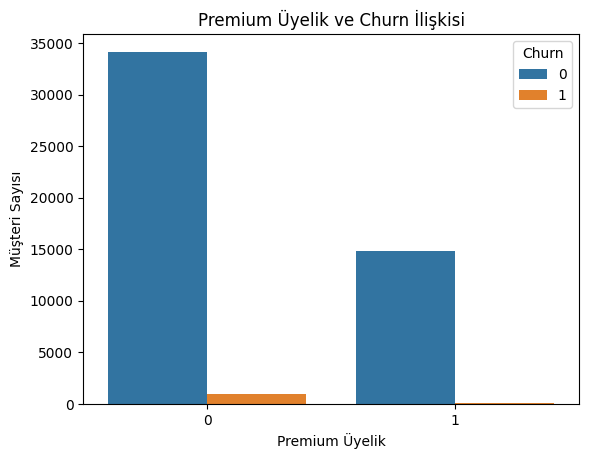

In [ ]:
sns.countplot(data=df, x='is_premium_plan', hue='churn')
plt.title('Premium Üyelik ve Churn İlişkisi')
plt.xlabel('Premium Üyelik')
plt.ylabel('Müşteri Sayısı')
plt.legend(title='Churn')
plt.show()

Veriye göre müşterilerin büyük bir kısmı hizmeti kullanmaya devam ediyor (churn = 0). Bu durum, genel müşteri memnuniyetinin yüksek olabileceğini ve sistemin çoğu kullanıcıyı elde tutabildiğini gösterir. Ancak azınlıkta da olsa bir müşteri kaybı (churn = 1) söz konusu.

**Adım 11:** is_premium_plan ve has_multiple_devices değişkenlerinin dağılımlarını göstermek için bar plot
grafiklerini oluştur.

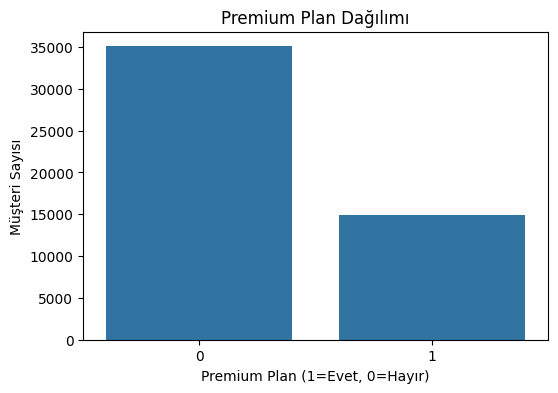

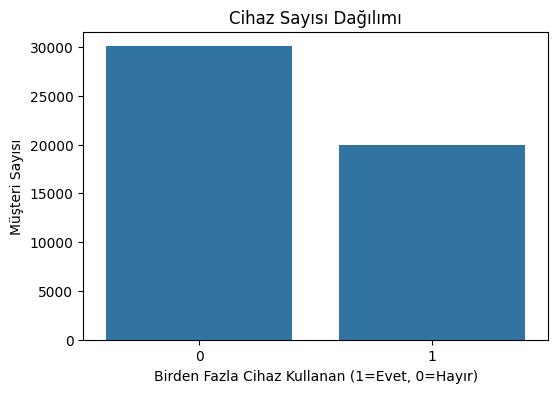

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Bar plot: is_premium_plan
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='is_premium_plan')
plt.title('Premium Plan Dağılımı')
plt.xlabel('Premium Plan (1=Evet, 0=Hayır)')
plt.ylabel('Müşteri Sayısı')
plt.show()

# Bar plot: has_multiple_devices
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='has_multiple_devices')
plt.title('Cihaz Sayısı Dağılımı')
plt.xlabel('Birden Fazla Cihaz Kullanan (1=Evet, 0=Hayır)')
plt.ylabel('Müşteri Sayısı')
plt.show()

Müşterilerin büyük çoğunluğu premium plan kullanmamaktadır. Bu durum, standart planların daha popüler olduğunu veya kullanıcıların ek ücretli hizmetleri tercih etmediğini gösterebilir. Şirketin premium plana geçişi teşvik edici stratejiler geliştirmesi gerekebilir.

**Adım 12:**
Customer_support_calls ve payment_failures sütunlarının dağılımını görmek için bar plot grafiklerini oluştur.
monthly_usage_hours ve tenure_months sütunlarının dağılımını incelemek için histogram grafiklerini oluştur.

<ipython-input-20-0a5cbe21a919>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='customer_support_calls', palette='coolwarm')


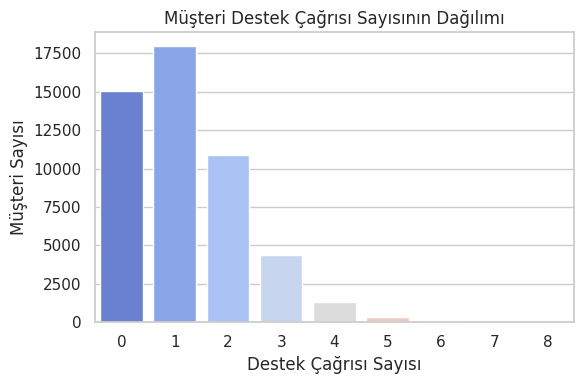

<ipython-input-20-0a5cbe21a919>:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='payment_failures', palette='Oranges')


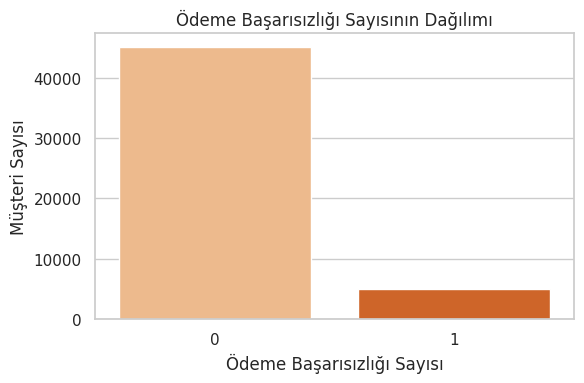

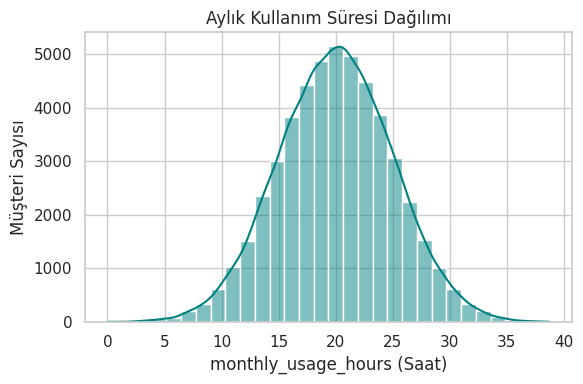

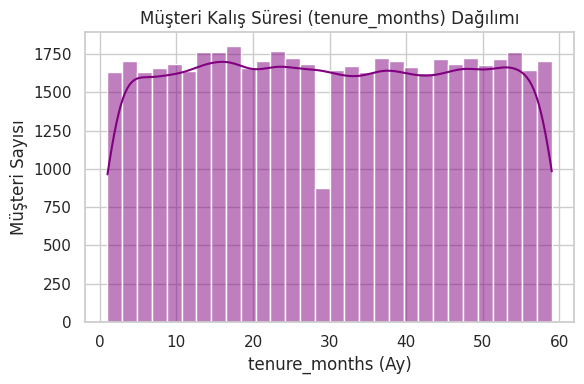

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# 1. Bar Plot: customer_support_calls (SibSp benzeri)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='customer_support_calls', palette='coolwarm')
plt.title('Müşteri Destek Çağrısı Sayısının Dağılımı')
plt.xlabel('Destek Çağrısı Sayısı')
plt.ylabel('Müşteri Sayısı')
plt.tight_layout()
plt.show()

# 2. Bar Plot: payment_failures (Parch benzeri)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='payment_failures', palette='Oranges')
plt.title('Ödeme Başarısızlığı Sayısının Dağılımı')
plt.xlabel('Ödeme Başarısızlığı Sayısı')
plt.ylabel('Müşteri Sayısı')
plt.tight_layout()
plt.show()

# 3. Histogram: monthly_usage_hours (Fare benzeri)
plt.figure(figsize=(6, 4))
sns.histplot(df['monthly_usage_hours'], bins=30, kde=True, color='teal')
plt.title('Aylık Kullanım Süresi Dağılımı')
plt.xlabel('monthly_usage_hours (Saat)')
plt.ylabel('Müşteri Sayısı')
plt.tight_layout()
plt.show()

# 4. Histogram: tenure_months (Age benzeri)
plt.figure(figsize=(6, 4))
sns.histplot(df['tenure_months'], bins=30, kde=True, color='purple')
plt.title('Müşteri Kalış Süresi (tenure_months) Dağılımı')
plt.xlabel('tenure_months (Ay)')
plt.ylabel('Müşteri Sayısı')
plt.tight_layout()
plt.show()

🔎 **1. customer_support_calls – Bar Plot Yorumu**
Ne gösteriyor? Müşterilerin müşteri hizmetleriyle kaç kez iletişime geçtiği.

✅ Olası Yorumlar:
0–1 çağrı yapan müşteriler en fazla olabilir, çünkü çoğu müşteri destek hattını sık aramaz.

Çok fazla çağrı yapanlar azınlıkta olabilir ama churn riski yüksek olabilir → Memnun olmayan kullanıcı olabilir.

Eğer 5+ çağrı yapanlarda churn oranı yüksekse, bu grubun özel ilgilenilmesi gerekebilir.

🔎** 2. payment_failures – Bar Plot Yorumu**
Ne gösteriyor? Müşterinin yaşadığı ödeme sorunlarının sayısı.

✅ Olası Yorumlar:
0 ödeme sorunu yaşayanların sayısı büyük ihtimalle yüksektir → bu iyi bir işaret.

1+ başarısızlık durumlarında müşteri memnuniyetsizliği artabilir.

Eğer ödeme problemi arttıkça churn oranı da artıyorsa, finansal işlem altyapısında iyileştirme gerekebilir.

🔎 **3. monthly_usage_hours – Histogram Yorumu**
Ne gösteriyor? Aylık toplam kullanım süresi (örneğin bir dijital platformda geçirilen saatler).

✅ Olası Yorumlar:
Dağılım sağa çarpık olabilir → çoğu kullanıcı ortalama sürede kullanırken, az sayıda heavy-user çok fazla saat harcayabilir.

Çok az kullanım gösteren kullanıcılar daha yüksek churn riskine sahip olabilir.

Eğer düşük saat kullanımı = yüksek churn, kullanıcıyı uygulamaya bağlayacak özellikler (bildirim, promosyon, içerik) artırılmalı.

🔎 **4. tenure_months – Histogram Yorumu**
Ne gösteriyor? Müşterinin şirkette kaldığı süre (ay cinsinden).

✅ Olası Yorumlar:
Yeni kullanıcıların (örneğin 0–3 ay kalanlar) sayısı fazla olabilir → doğal churn oranı da burada yüksek olabilir.

Uzun süre kalan müşteriler genelde daha sadıktır.

Eğer churn oranı en çok ilk birkaç ayda görülüyorsa, onboarding süreci zayıf olabilir.

| Gözlem                            | Aksiyon Fikri                            |
| --------------------------------- | ---------------------------------------- |
| Çok destek çağrısı → yüksek churn | Daha iyi destek, kişiselleştirme         |
| Ödeme sorunu → churn artıyor      | Finansal sistemlerin güçlendirilmesi     |
| Düşük kullanım süresi → churn     | Kullanıcıyı içeriğe bağlayan tasarımlar  |
| Erken churn yüksek                | Yeni müşteri için özel onboarding süreci |

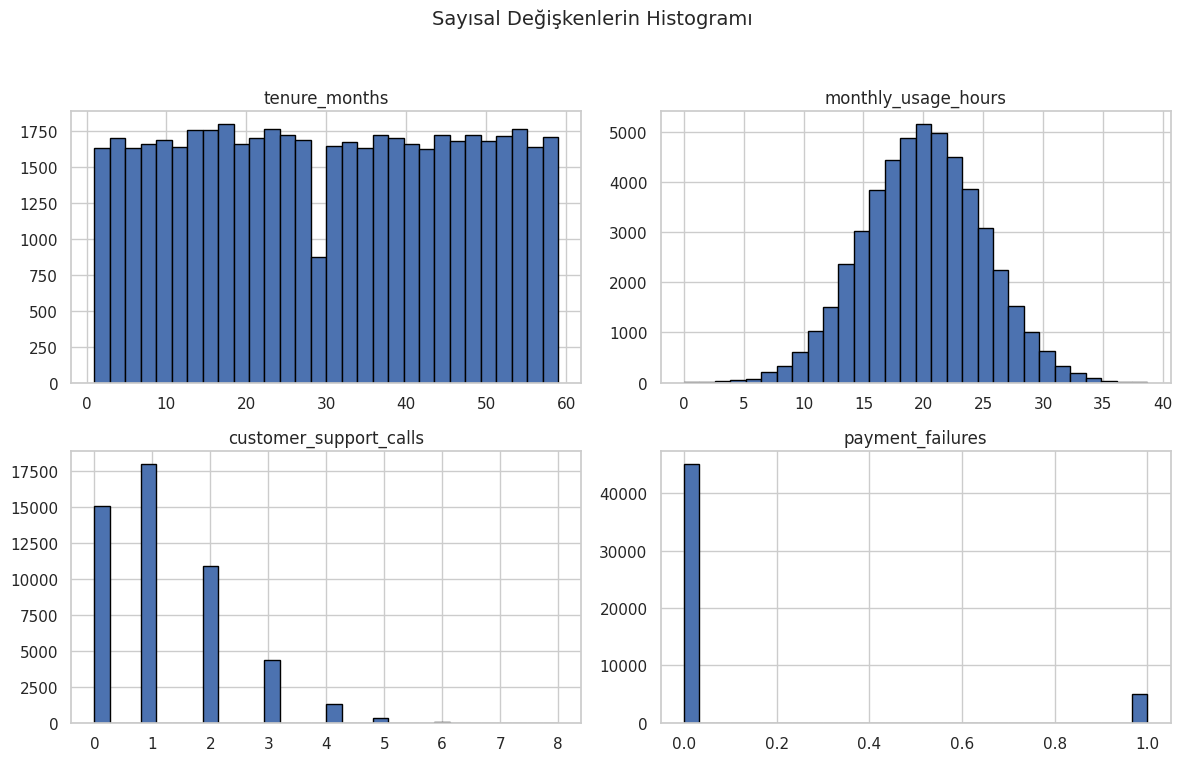

In [ ]:
import matplotlib.pyplot as plt

# Sayısal değişkenleri seç
numeric_columns = ['tenure_months', 'monthly_usage_hours', 'customer_support_calls', 'payment_failures']

# Histogram çizimi
df[numeric_columns].hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.suptitle("Sayısal Değişkenlerin Histogramı", fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Başlık ile grafiklerin çakışmaması için
plt.show()

1️⃣ tenure_months – Müşterinin sistemde kalma süresi (ay)
📉 Dağılım sola çarpık olabilir:
Çoğu müşteri kısa süre kalmış. Bu, hizmetten memnun kalmayan veya denemek için gelen kullanıcıların fazla olduğunu gösterebilir.

🔢 Belirgin bir tepe noktası varsa (örneğin 1–3 ay): Bu ay aralığı churn riski açısından kritik olabilir.

2️⃣ monthly_usage_hours – Aylık kullanım süresi (saat)
🔺 Eğer dağılım simetrikse veya çan eğrisi gibiyse: Kullanıcıların çoğu benzer şekilde platformu kullanıyor demektir.

🧭 Eğer çok düşük kullanım saatlerinde yoğunluk varsa: Aktif olmayan kullanıcılar churn riski taşır.

📌 Uç noktada birkaç çok aktif kullanıcı varsa (outlier), bu müşteriler sadık ve değerli segment olabilir.

3️⃣ customer_support_calls – Destek çağrısı sayısı
🔢 Genellikle 0–2 arasında yoğunluk gözlenir.

📈 Eğer çağrı sayısı 5 veya daha fazla olanlar da varsa: Bunlar memnuniyetsiz kullanıcılar olabilir.

📉 Çok az çağrı yapanlar memnun olabilir ya da hiç destek aramadan sistemden ayrılmış olabilir.

4️⃣ payment_failures – Ödeme hatası sayısı
✅ Sıfır ödeme hatasında büyük yoğunluk olur (çoğu müşteri sorun yaşamamış).

⚠ 1–2 ödeme hatası yapan müşteriler ayrılmış olabilir → churn riski artar.

❗ Yüksek hata sayısına sahip kullanıcılar varsa, sistemsel ya da bireysel sorunlar olabilir.

<ipython-input-22-6428fae5def1>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df["churn"], y=df["customer_support_calls"], palette="pastel")


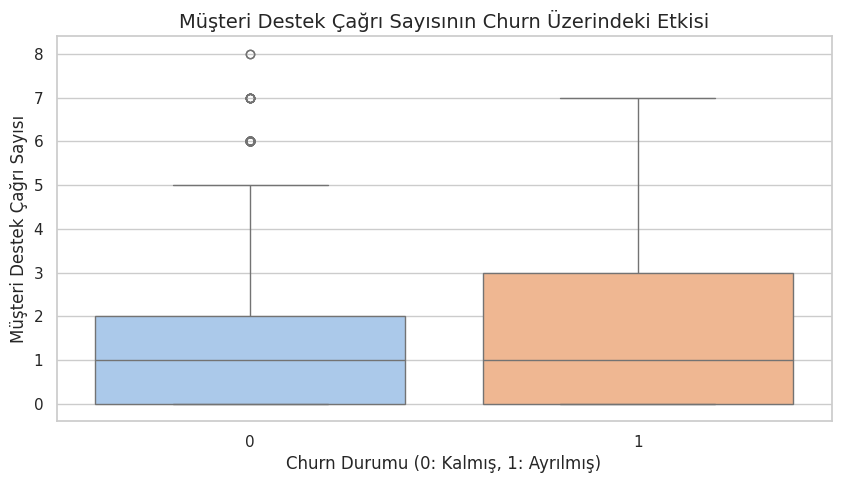

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.boxplot(x=df["churn"], y=df["customer_support_calls"], palette="pastel")

plt.title("Müşteri Destek Çağrı Sayısının Churn Üzerindeki Etkisi", fontsize=14)
plt.xlabel("Churn Durumu (0: Kalmış, 1: Ayrılmış)", fontsize=12)
plt.ylabel("Müşteri Destek Çağrı Sayısı", fontsize=12)
plt.show()

🔁 Müşteri destek çağrısı sayısı arttıkça churn etme olasılığı da artıyor gibi görünüyor.

Bu da şu anlama gelir:

+Destek birimini aramak zorunda kalan müşteriler, yaşadığı sorunları çözememiş olabilir.

+Destek çağrısı sayısı belli bir eşiği geçtiğinde (örneğin ≥3), sistem otomatik olarak “riskli müşteri” olarak işaretleyebilir.

+Proaktif destek önerilebilir: "Sizi memnun etmek için buradayız" gibi iletişimler churn'ü azaltabilir.

# 6. AKADEMİK ÇALIŞMALAR İÇİN DAHA PROFESYONEL GÖRSELLER

**Adım 13:** tenure_months ve churn sütunları için density plot (yoğunluk grafiği) oluştur.

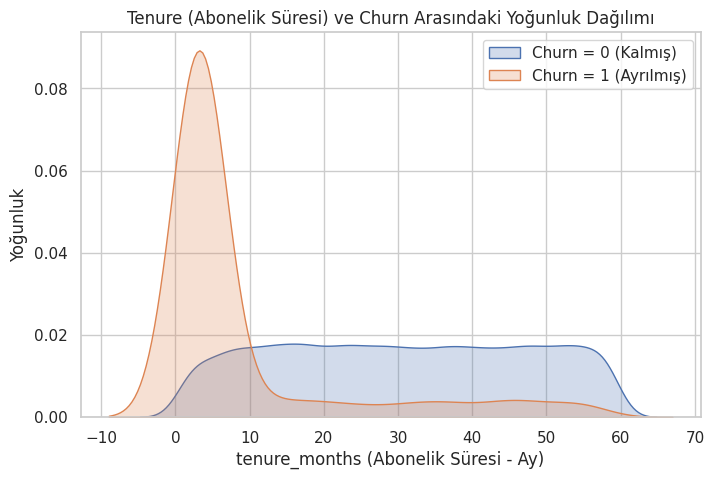

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# churn = 0 olanlar (hizmeti bırakmayanlar)
sns.kdeplot(df[df['churn'] == 0]['tenure_months'], label='Churn = 0 (Kalmış)', fill=True)

# churn = 1 olanlar (hizmeti bırakanlar)
sns.kdeplot(df[df['churn'] == 1]['tenure_months'], label='Churn = 1 (Ayrılmış)', fill=True)

plt.title('Tenure (Abonelik Süresi) ve Churn Arasındaki Yoğunluk Dağılımı')
plt.xlabel('tenure_months (Abonelik Süresi - Ay)')
plt.ylabel('Yoğunluk')
plt.legend()
plt.show()

**Eğer churn = 1 olan müşterilerin yoğunluğu düşük tenure_months değerlerinde yoğunlaşmışsa:**
Yeni müşteriler daha hızlı ayrılıyor. Bu durum, ilk aylar içinde kullanıcı deneyiminin yeterince iyi olmadığını gösterebilir. Kullanıcıların sadakatini artırmak için onboarding (ilk deneyim), destek ve teşvik süreçleri güçlendirilmeli.

**Eğer churn = 1 ve churn = 0 grupları birbirine çok yakınsa:**
Churn davranışı abonelik süresiyle güçlü bir şekilde ayrışmıyor olabilir. Diğer faktörlerin daha belirleyici olduğu düşünülmeli (örneğin: ödeme sorunları, destek çağrısı sayısı vs.).

**Adım 14:** is_premium_plan değişkeni ile gruplandırılmış tenure_months churn sütunları için density plot (yoğunluk grafiği) oluştur.

<ipython-input-24-97592ca50aba>:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='is_premium_plan (0 = Normal, 1 = Premium)')


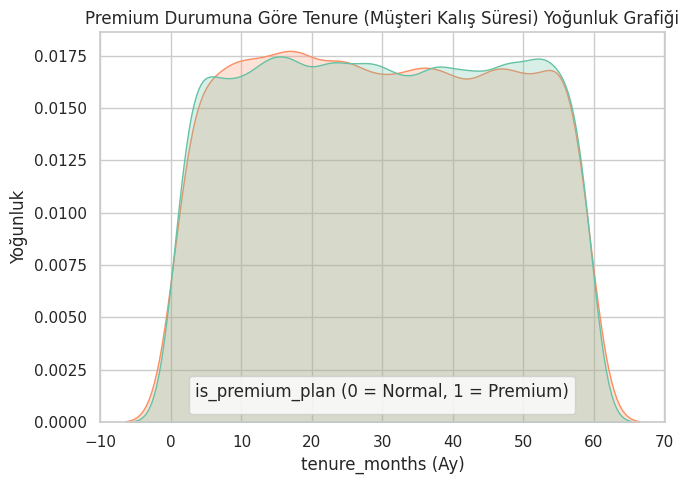

<ipython-input-24-97592ca50aba>:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='is_premium_plan (0 = Normal, 1 = Premium)')


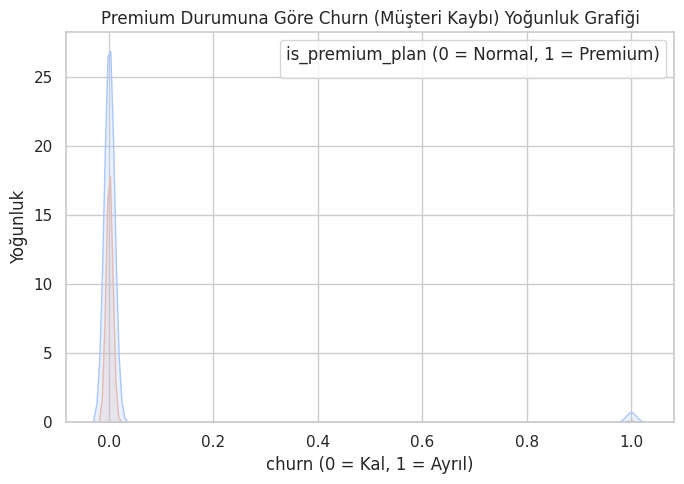

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# 1. tenure_months için yoğunluk grafiği (is_premium_plan gruplu)
plt.figure(figsize=(7, 5))
sns.kdeplot(data=df, x='tenure_months', hue='is_premium_plan', fill=True, common_norm=False, palette='Set2')
plt.title('Premium Durumuna Göre Tenure (Müşteri Kalış Süresi) Yoğunluk Grafiği')
plt.xlabel('tenure_months (Ay)')
plt.ylabel('Yoğunluk')
plt.legend(title='is_premium_plan (0 = Normal, 1 = Premium)')
plt.tight_layout()
plt.show()

# 2. churn için yoğunluk grafiği (is_premium_plan gruplu)
plt.figure(figsize=(7, 5))
sns.kdeplot(data=df, x='churn', hue='is_premium_plan', fill=True, bw_adjust=0.5, palette='coolwarm')
plt.title('Premium Durumuna Göre Churn (Müşteri Kaybı) Yoğunluk Grafiği')
plt.xlabel('churn (0 = Kal, 1 = Ayrıl)')
plt.ylabel('Yoğunluk')
plt.legend(title='is_premium_plan (0 = Normal, 1 = Premium)')
plt.tight_layout()
plt.show()

1. Müşterinin Kalma Süresi (tenure_months) – Premium ve Normal Müşteriler
Premium müşterilerin kalma süresi daha uzun.
Yani, premium plan kullananlar şirketle daha uzun süre kalıyor, onları bırakma olasılıkları daha düşük.

Normal müşteriler ise genellikle daha kısa kalıyor.
Bu grup, daha çabuk ayrılma eğiliminde.

Ne anlıyoruz?
Premium plan müşteriyi daha fazla bağlıyor, sadakat artırıyor.

2. Müşteri Kaybı (churn) – Premium ve Normal Müşteriler
Premium müşteriler daha az ayrılıyor.
Yani churn (müşteri kaybı) oranı premiumlarda düşük.

Normal müşterilerde müşteri kaybı daha fazla.

Ne anlıyoruz?
Premium plan, müşterinin hizmetten ayrılmasını engelliyor.


**Adım 15**: is_premium_plan sütununa göre churn ve tenure_months
sütunlarının yoğunluk dağılımını içeren density plot (yoğunluk grafiği) oluştur.

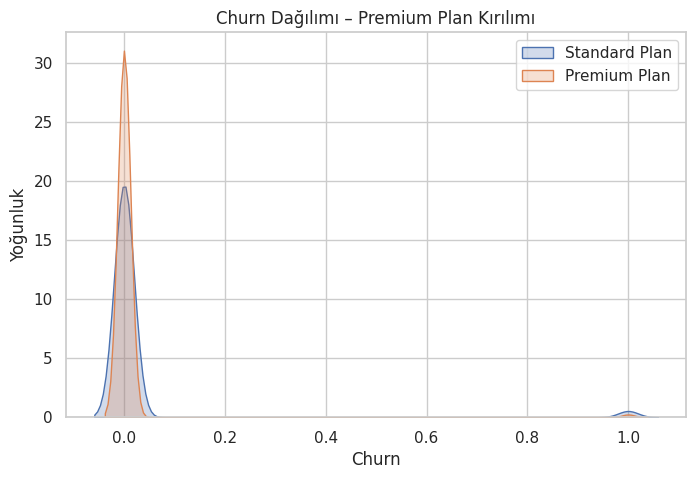

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Premium olmayanlar
sns.kdeplot(df[df['is_premium_plan'] == 0]['churn'], label='Standard Plan', fill=True)

# Premium kullanıcılar
sns.kdeplot(df[df['is_premium_plan'] == 1]['churn'], label='Premium Plan', fill=True)

plt.title('Churn Dağılımı – Premium Plan Kırılımı')
plt.xlabel('Churn')
plt.ylabel('Yoğunluk')
plt.legend()
plt.show()

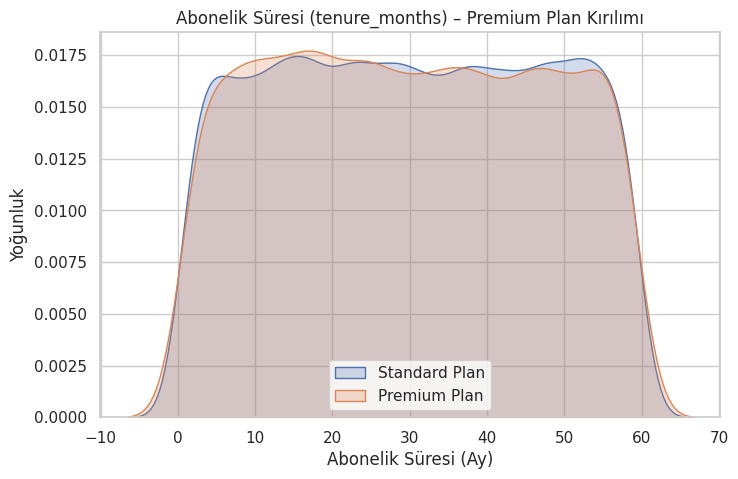

In [ ]:
plt.figure(figsize=(8, 5))

# Standard kullanıcılar
sns.kdeplot(df[df['is_premium_plan'] == 0]['tenure_months'], label='Standard Plan', fill=True)

# Premium kullanıcılar
sns.kdeplot(df[df['is_premium_plan'] == 1]['tenure_months'], label='Premium Plan', fill=True)

plt.title('Abonelik Süresi (tenure_months) – Premium Plan Kırılımı')
plt.xlabel('Abonelik Süresi (Ay)')
plt.ylabel('Yoğunluk')
plt.legend()
plt.show()

Eğer premium kullanıcılar daha uzun süre sistemde kalmışsa:
Premium kullanıcılar genellikle daha uzun süreli bağlılık gösteriyor. Bu, planın fayda sağladığını veya bu kullanıcıların genel olarak daha bağlı olduğunu gösterir.

Eğer premium kullanıcılar arasında churn oranı daha düşükse:
Premium plan müşteri kaybını azaltmakta etkili olabilir. Bu, değer önerisinin güçlü olduğunu ve kullanıcıların planı faydalı bulduğunu gösterir.

# 7. KORELASYON ANALİZİ

**Adım 16:** veri setindeki tüm sayısal sütunlar arasındaki korelasyonları hesapla ve bu
korelasyonları bir heatmap (ısı haritası) üzerinde görselleştir.

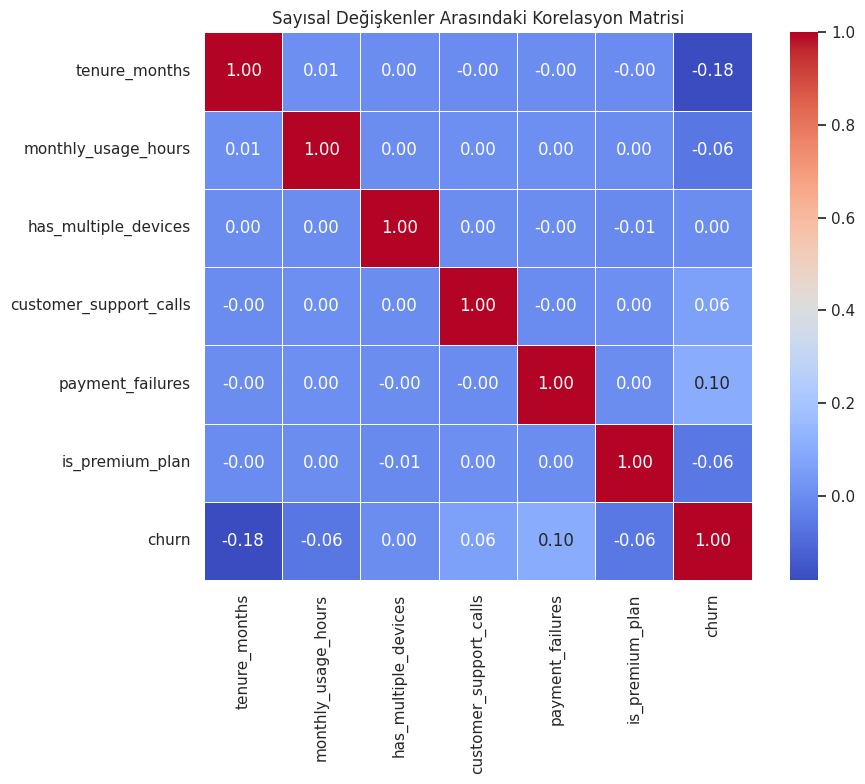

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sayısal sütunları seç
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Korelasyon matrisi oluştur
corr_matrix = df[numerical_cols].corr()

# Heatmap ile görselleştir
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
plt.title('Sayısal Değişkenler Arasındaki Korelasyon Matrisi')
plt.tight_layout()
plt.show()

Değişken	churn ile Korelasyon	Yorum
+tenure_months	-0.18	Müşteri şirkette ne kadar uzun süre kalmışsa, ayrılma ihtimali azalıyor. Ama bu ilişki zayıf düzeyde. Yine de bu değişken anlamlı olabilir.

+monthly_usage_hours	-0.06	Kullanım süresi ile müşteri kaybı arasında neredeyse hiç ilişki yok. Yani çok veya az kullananın ayrılma olasılığı benzer olabilir.

+has_multiple_devices	0.00	Birden fazla cihaz kullanmak ile churn arasında hiç ilişki yok gibi. Bu değişken bilgi taşımıyor olabilir.

+customer_support_calls	0.06	Destek arama sayısı arttıkça çok küçük bir olasılıkla müşteri ayrılabilir ama ilişki anlamsız düzeyde düşük.

+payment_failures	0.10	Ödeme başarısızlıkları biraz etkili olabilir, çünkü pozitif ve diğerlerine göre daha yüksek. Yani ödeme sıkıntısı yaşayanlar ayrılmaya daha meyilli olabilir.

+is_premium_plan	-0.06	Premium plan kullananlarda churn biraz daha düşük olabilir, ama ilişki çok zayıf.

+churn	1.00	Kendisiyle birebir tam korelasyon gösterir (referans).

**Hiçbir değişkenin korelasyonu |0.2|’nin üzerine çıkmamış, bu da modelleme için doğrudan anlamlı güçlü ilişkilerin olmadığını gösteriyor.
Ama bu:
Değişkenlerin önemsiz olduğu anlamına gelmez
Yalnızca doğrusal ilişkilerin zayıf olduğunu gösterir**

# 8. KATEGORİK VERİ ANALİZİ

**Adım 17:** veri setindeki kategorik değişkenlerin sıklığını incelemek için **value_counts()**
fonksiyonunu kullanmama yardımcı olun. Bu dağılımı görselleştirecek uygun bir yöntem de
önerin.

In [ ]:
# is_premium_plan dağılımı
print("is_premium_plan dağılımı:")
print(df['is_premium_plan'].value_counts())
print("\n")

# has_multiple_devices dağılımı
print("has_multiple_devices dağılımı:")
print(df['has_multiple_devices'].value_counts())
print("\n")

# churn dağılımı
print("churn dağılımı:")
print(df['churn'].value_counts())
print("\n")

is_premium_plan dağılımı:
is_premium_plan
0    35083
1    14917
Name: count, dtype: int64


has_multiple_devices dağılımı:
has_multiple_devices
0    30059
1    19941
Name: count, dtype: int64


churn dağılımı:
churn
0    48967
1     1033
Name: count, dtype: int64




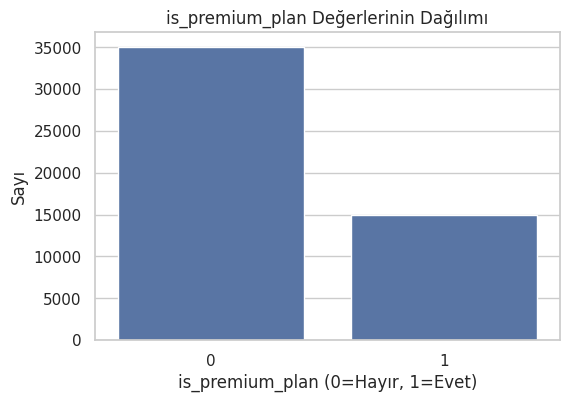

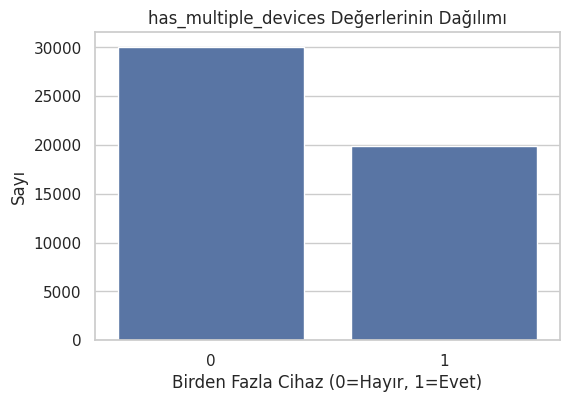

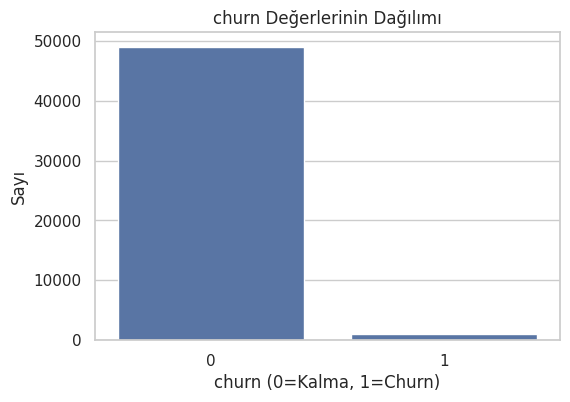

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# is_premium_plan bar plot
plt.figure(figsize=(6,4))
sns.countplot(x='is_premium_plan', data=df)
plt.title('is_premium_plan Değerlerinin Dağılımı')
plt.xlabel('is_premium_plan (0=Hayır, 1=Evet)')
plt.ylabel('Sayı')
plt.show()

# has_multiple_devices bar plot
plt.figure(figsize=(6,4))
sns.countplot(x='has_multiple_devices', data=df)
plt.title('has_multiple_devices Değerlerinin Dağılımı')
plt.xlabel('Birden Fazla Cihaz (0=Hayır, 1=Evet)')
plt.ylabel('Sayı')
plt.show()

# churn bar plot
plt.figure(figsize=(6,4))
sns.countplot(x='churn', data=df)
plt.title('churn Değerlerinin Dağılımı')
plt.xlabel('churn (0=Kalma, 1=Churn)')
plt.ylabel('Sayı')
plt.show()

+Eğer is_premium_plan sütununda 1 değeri azsa → müşterilerin büyük çoğunluğu standart plan kullanıyor.

+has_multiple_devices 1 değeri çoksa → müşteriler çoğunlukla birden fazla cihaz kullanıyor.

+churn değerinin 1 oranı düşükse → müşteri kaybı oranı makul seviyede, yüksekse sorun var.

Bu grafikler sana her kategorik değişkenin veri setindeki dağılımını net gösterir.

**Adım 18:** İki kategorik değişken arasındaki ilişkiyi incelemek için **pd.crosstab()** fonksiyonunu
kullanarak veri setindeki iki kategorik değişkenin ilişkisini analiz etmemi sağlar.
Sonuçları anlamak için uygun görselleştirme yöntemini önerir.

In [ ]:
import pandas as pd

# is_premium_plan ile churn arasındaki çapraz tablo (contingency table)
ct = pd.crosstab(df['is_premium_plan'], df['churn'], margins=True)

print(ct)

churn                0     1    All
is_premium_plan                    
0                34164   919  35083
1                14803   114  14917
All              48967  1033  50000


Premium plan kullanıcıları, çok daha düşük bir oranda hizmeti bırakıyor.

Churn oranı standart kullanıcılar için 3 kat daha fazla (%2.62 vs. %0.76).

➡ Bu durum, premium planın müşteri sadakatini artırmada etkili olduğunu açıkça gösteriyor. Premium kullanıcılar muhtemelen hizmetten daha memnun veya daha bağlı hissediyorlar.

**Adım 19:**  veri setindeki kategorik değişkenlerin dağılımını görselleştirmek için
**sns.countplot() ve sns.barplot()** fonksiyonları ile etkili bir şekilde görselleştirmemi sağlar. Bu
görselleştirmelerle her kategorik değişkenin genel dağılımını incelememi sağlar.

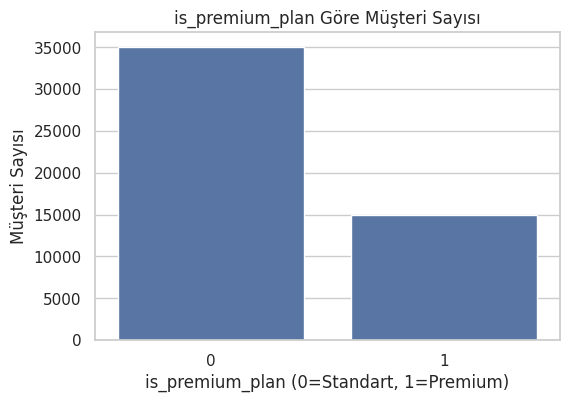

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.countplot(x='is_premium_plan', data=df)
plt.title('is_premium_plan Göre Müşteri Sayısı')
plt.xlabel('is_premium_plan (0=Standart, 1=Premium)')
plt.ylabel('Müşteri Sayısı')
plt.show()

Çoğunluk (yaklaşık %70) standart plan kullanıyor.

Premium plan kullanıcıları daha az sayıda, ama önceki analizlere göre daha az churn oranına sahipler.

Bu durum, premium planın özel avantajlara rağmen daha az tercih edildiğini, ancak tercih edenlerin daha memnun olabileceğini gösteriyor.

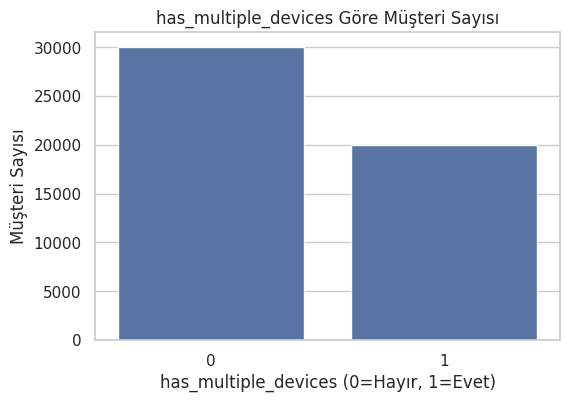

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='has_multiple_devices', data=df)
plt.title('has_multiple_devices Göre Müşteri Sayısı')
plt.xlabel('has_multiple_devices (0=Hayır, 1=Evet)')
plt.ylabel('Müşteri Sayısı')
plt.show()

Müşterilerin çoğu birden fazla cihaz kullanıyor olabilir. Bu, dijital bağlılık ve aktif kullanım göstergesidir.

Aynı zamanda, birden fazla cihaz kullanan müşterilerin churn olasılığı düşük olabilir; çünkü sistemle daha entegre olmuşlardır.

Eğer çoğunluk 0 ise:

Kullanıcılar çoğunlukla tek bir cihaz üzerinden bağlanıyor olabilir. Bu durumda kullanım çeşitliliği düşük ve sadakat daha zayıf olabilir.

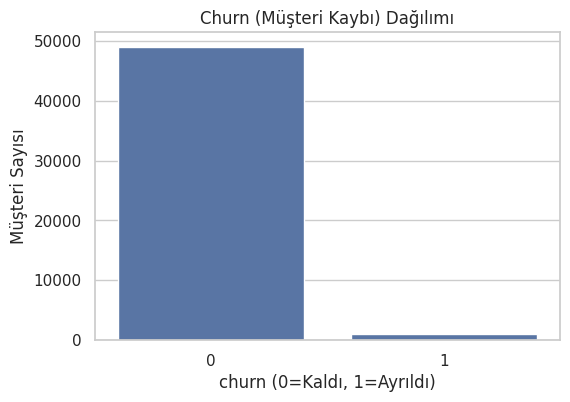

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='churn', data=df)
plt.title('Churn (Müşteri Kaybı) Dağılımı')
plt.xlabel('churn (0=Kaldı, 1=Ayrıldı)')
plt.ylabel('Müşteri Sayısı')
plt.show()

Genel churn oranı %2.07 civarında, bu da oldukça düşük.

Bu, şirketin müşteri memnuniyeti açısından güçlü olduğunu gösteriyor olabilir.

Ancak, premium kullanıcılarda churn çok daha düşük olduğundan, premium planın yaygınlaştırılması churn’ü daha da azaltabilir.

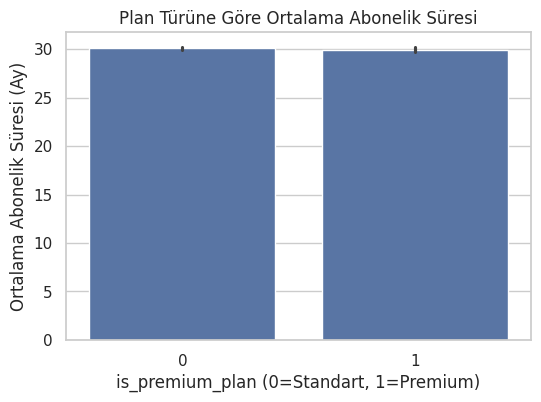

In [ ]:
plt.figure(figsize=(6,4))
sns.barplot(x='is_premium_plan', y='tenure_months', data=df)
plt.title('Plan Türüne Göre Ortalama Abonelik Süresi')
plt.xlabel('is_premium_plan (0=Standart, 1=Premium)')
plt.ylabel('Ortalama Abonelik Süresi (Ay)')
plt.show()

Bu grafik, premium kullanıcıların sisteme daha bağlı (daha uzun süre kalmış) olup olmadığını gösterir.

**Adım 20:**  veri setindeki sayısal değişkenler arasındaki ilişkileri analiz etmek için
**pairplot()** fonksiyonlarını kullanarak çok değişkenli analiz yapmamı sağlar.
Bu ilişkileri görselleştirme adımında kullanılacak en uygun metodolojiyi önerir.

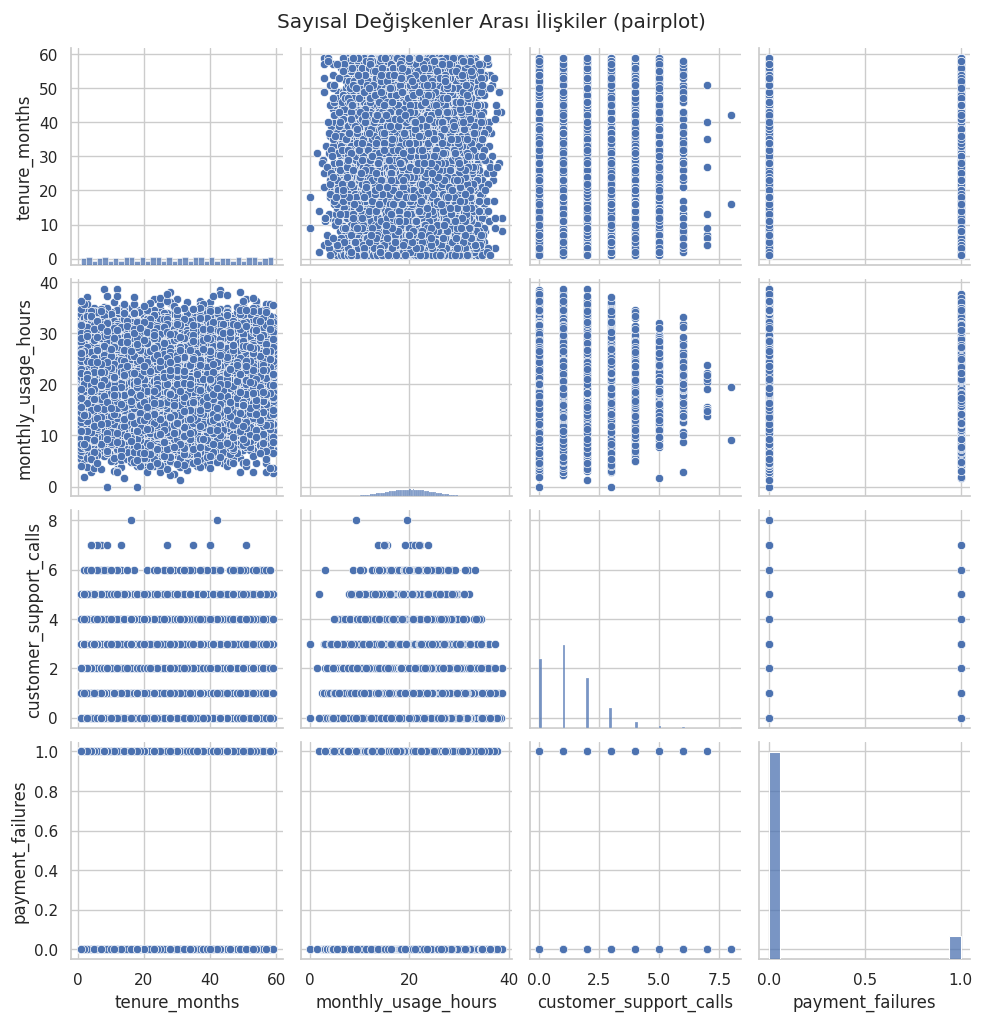

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Sayısal sütunları seç
num_cols = ['tenure_months', 'monthly_usage_hours', 'customer_support_calls', 'payment_failures']

# Pairplot çizimi
sns.pairplot(df[num_cols])
plt.suptitle("Sayısal Değişkenler Arası İlişkiler (pairplot)", y=1.02)
plt.show()

1. tenure_months vs monthly_usage_hours
Scatter plot'a göre bu iki değişken arasında belirgin bir korelasyon gözlenmeyebilir.

Kullanım süresi uzun olanların mutlaka daha fazla kullandığını gösteren bir desen görünmüyor olabilir.

Ancak bazı kullanıcılar hem uzun süre kalmış hem de fazla saat kullanmış olabilir → sadık ve aktif müşteri profili.

🔹 2. tenure_months vs customer_support_calls
Eğer çağrı sayısı arttıkça abonelik süresi azalıyor gibi bir desen varsa:

Müşteri destek aramaları memnuniyetsizlik belirtisi olabilir, bu da erken ayrılmaya yol açabilir.

Yoksa, çağrı sayısı ile süre arasında bir ilişki gözlemlenmiyorsa, bu destek çağrılarının churn üzerinde doğrudan etkisi olmayabilir.

🔹 3. tenure_months vs payment_failures
Scatter plot’ta ödeme hataları fazla olanların abonelik süresi genellikle düşükse:

Bu, ödeme sorunlarının erken ayrılma (churn) ile ilişkili olduğunu gösterir.

Aykırı değer olarak çok fazla başarısız ödeme yapıp hâlâ sistemde kalan kullanıcılar varsa, bu durum ayrıca incelenebilir.

🔹 4. monthly_usage_hours vs customer_support_calls
Yüksek kullanım yapanların daha çok destek araması doğal olabilir; ama destek arayanlar düşük kullanımda yoğunlaşıyorsa:

Kullanım deneyiminde sorun olabilir (örneğin: uygulama problemleri vs).

🔹 5. Diagonal Grafikler (Histogramlar):
Her bir değişkenin dağılımı şu şekilde yorumlanabilir:

tenure_months: Eğer sola yatık bir dağılım varsa, çoğu kullanıcı sistemde kısa süre kalıyor.

monthly_usage_hours: Ortalamanın etrafında yoğunluk varsa, kullanıcılar benzer davranışta.

customer_support_calls ve payment_failures: Genelde 0–2 arasında yoğunlaşma görülür, ama bazı yüksek uçlar (outlier) varsa sistemsel problemler olabilir.


# **EKSTRA**

In [ ]:
!pip install ydata-profiling

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.1/400.1 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 687.8/687.8 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.4 MB/s eta 0:00:00
  Created wheel for htmlmin: filename=htmlmin-0.1.12-py3-none-any.whl size=27081 sha256=0effcdee5f6b9a28d9f3e36b2bab7ae85818d9cd64e2a6a47b3964d39ce0144c
  Stored in directory: /root/.cache/pip/wheels/8d/55/1a/19cd535375ed1ede0c996405ebffe34b196d78e2d9545723a2
Successfully built htmlmin


In [ ]:
import pandas as pd
from ydata_profiling import ProfileReport

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/customer_churn_dataset.csv')

In [ ]:
profile = ProfileReport(df, title="Müşteri Churn Veri Seti EDA Raporu", explorative=True)

In [ ]:
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 7/7 [00:00<00:00, 11.42it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

# **II. Veri Ön İşleme**

In [ ]:
# Eksik değer analizi
missing_values_before = df.isnull().sum()
print("Eksik Değer Analizi (Önce):")
print(missing_values_before)

Eksik Değer Analizi (Önce):
tenure_months             0
monthly_usage_hours       0
has_multiple_devices      0
customer_support_calls    0
payment_failures          0
is_premium_plan           0
churn                     0
dtype: int64


In [ ]:
df.isnull().sum()

,0
tenure_months,0
monthly_usage_hours,0
has_multiple_devices,0
customer_support_calls,0
payment_failures,0
is_premium_plan,0
churn,0


In [ ]:
def remove_outliers_iqr(df, column):
    """ IQR yöntemi ile aykırı değerleri üst sınır ile değiştirir """
    Q1 = df[column].quantile(0.25)  # İlk çeyrek (Q1)
    Q3 = df[column].quantile(0.75)  # Üçüncü çeyrek (Q3)
    IQR = Q3 - Q1  # Interquartile Range (IQR)

    lower_bound = Q1 - 1.5 * IQR  # Alt sınır
    upper_bound = Q3 + 1.5 * IQR  # Üst sınır

    # Aykırı değerleri üst sınır ile değiştirme
    df[column] = df[column].apply(lambda x: upper_bound if x > upper_bound else x)

    return df

# tenure_months ve monthly_usage_hours sütunları için IQR yöntemi ile aykırı değerleri temizleme
df = remove_outliers_iqr(df, 'tenure_months')
df = remove_outliers_iqr(df, 'monthly_usage_hours')

<ipython-input-44-bae01c203ba4>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df["is_premium_plan"], y=df["monthly_usage_hours"], palette="Set1")


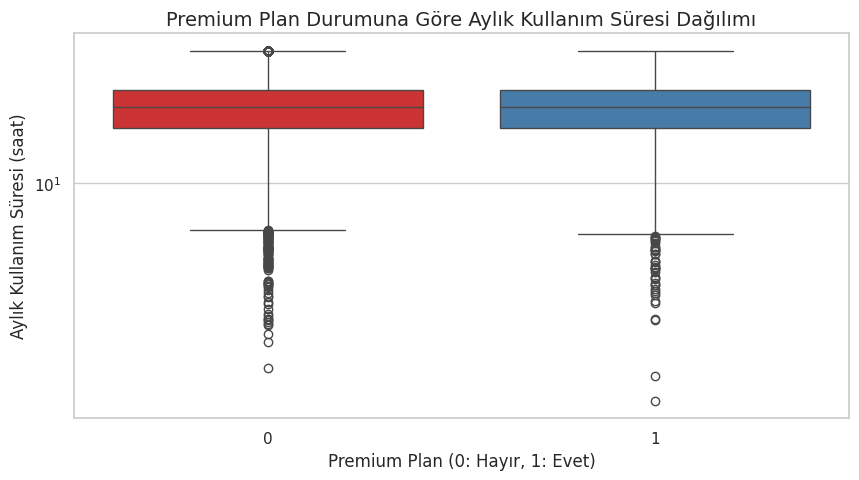

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.boxplot(x=df["is_premium_plan"], y=df["monthly_usage_hours"], palette="Set1")

plt.title("Premium Plan Durumuna Göre Aylık Kullanım Süresi Dağılımı", fontsize=14)
plt.xlabel("Premium Plan (0: Hayır, 1: Evet)", fontsize=12)
plt.ylabel("Aylık Kullanım Süresi (saat)", fontsize=12)
plt.yscale("log")  # Kullanım saatleri arasında büyük farklılıklar olabilir
plt.show()

Premium plan kullanıcıları, ortalamada biraz daha fazla saat kullanım göstermiş. Bu, premium planın gerçekten daha fazla kullanım sağladığını hafifçe destekliyor ama fark çok belirgin değil.

Her iki grubun da ortalama kullanımı benzer seviyelerde; yani premium kullanıcı olmak, dramatik bir kullanım artışı sağlamamış.

Logaritmik eksene rağmen, veri dağılımı oldukça benzer yapıda — premium planın etkisi sınırlı olabilir.

10¹ = 10 saat

🔍 Neden logaritmik eksen kullanıyoruz?
Çünkü veri kümesinde bazı kullanıcılar çok az (örneğin 1-5 saat), bazıları ise çok fazla (örneğin 100+ saat) zaman harcamış. Normal (lineer) eksen kullanıldığında küçük değerler kaybolur, büyükler baskın çıkar. Logaritmik ölçek, bu geniş dağılımı sıkıştırarak daha anlamlı bir görselleştirme sağlar.

In [ ]:
# ProblemLoad değişkenini oluşturma (customer_support_calls + payment_failures)
df['ProblemLoad'] = df['customer_support_calls'] + df['payment_failures']

# IsProblemFree değişkenini oluşturma (Hiç sorun yaşamadıysa 1, yaşadıysa 0)
df['IsProblemFree'] = (df['ProblemLoad'] == 0).astype(int)

In [ ]:

df.head()

,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn,ProblemLoad,IsProblemFree
0,39,30.953928,0,1,0,0,0,1,0
1,52,20.485203,0,0,0,0,0,0,1
2,29,21.684462,0,1,1,0,0,2,0
3,15,27.894281,0,1,0,1,0,1,0
4,43,19.250190,1,1,0,0,0,1,0


Anlamı:
Bu değişken, bir müşterinin toplamda kaç kez sorun yaşadığını gösterir.

customer_support_calls: Müşteri destek birimini arama sayısı

payment_failures: Ödeme başarısızlığı sayısı

Anlamı:
Bu değişken, müşterinin hiç sorun yaşayıp yaşamadığını gösterir.

1 → Müşteri hiç destek araması yapmamış ve hiç ödeme problemi yaşamamış, yani sorunsuz

0 → Müşteri bir veya birden fazla sorun yaşamış

In [ ]:
import numpy as np

def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = np.where(df[column] > upper_bound, upper_bound, df[column])
    df[column] = np.where(df[column] < lower_bound, lower_bound, df[column])
    return df

# Sayısal sütunlar listesi
numeric_columns = ['tenure_months', 'monthly_usage_hours', 'customer_support_calls', 'payment_failures']

# Her sayısal sütuna aykırı değer temizliği uygula
for col in numeric_columns:
    df = remove_outliers_iqr(df, col)

df.head()

,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn,ProblemLoad,IsProblemFree
0,39.0,30.953928,0,1.0,0.0,0,0,1,0
1,52.0,20.485203,0,0.0,0.0,0,0,0,1
2,29.0,21.684462,0,1.0,0.0,0,0,2,0
3,15.0,27.894281,0,1.0,0.0,1,0,1,0
4,43.0,19.250190,1,1.0,0.0,0,0,1,0


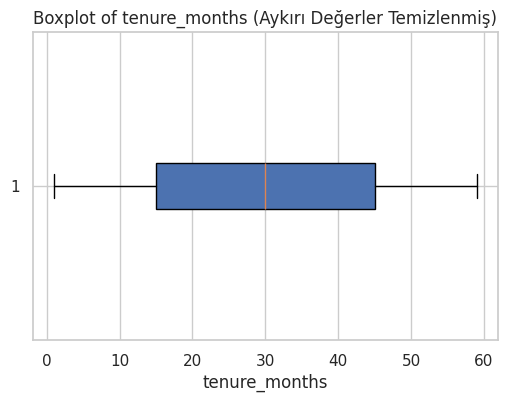

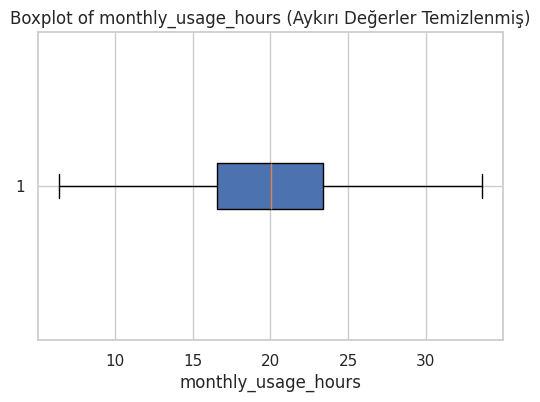

In [ ]:
import matplotlib.pyplot as plt

# Boxplot çizme fonksiyonu
def plot_boxplot(df, column):
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[column], vert=False, patch_artist=True)
    plt.title(f"Boxplot of {column} (Aykırı Değerler Temizlenmiş)")
    plt.xlabel(column)
    plt.show()

# tenure_months ve monthly_usage_hours için boxplot çizme
plot_boxplot(df, 'tenure_months')
plot_boxplot(df, 'monthly_usage_hours')

1. tenure_months Boxplot Yorumu
Medyan (kutunun içindeki çizgi) veri setindeki müşterilerin ortalama abonelik süresini gösterir.

Kutunun genişliği (IQR), yani Q1 ve Q3 arasındaki mesafe, abonelik süresinin çoğunlukla hangi aralıkta yoğunlaştığını gösterir.

Alt ve üst limitler (whisker’lar) aykırı değerlerin temizlenmesiyle artık çok uç değerlere gitmiyor, böylece veri setindeki ekstrem abonelik süreleri sınırlandırıldı.

Böylece, aşırı uzun ya da aşırı kısa abonelik süreleri artık modele aşırı etki etmeyecek.

2. monthly_usage_hours Boxplot Yorumu
Medyan aylık kullanım saatinin genellikle hangi seviyede olduğunu gösterir.

IQR içindeki çoğunluk müşterinin aylık kullanım süresi yoğunluğunu yansıtır.

Önceden uç değerler (çok yüksek kullanım saatleri) vardıysa, bunlar IQR yöntemiyle sınırlandırıldı, artık grafik daha simetrik ve uçlardan temiz.

Bu sayede aşırı yoğun ya da çok düşük kullanım saatleri modeli bozmayacak.

In [ ]:
df['ProblemLoad'] = df['customer_support_calls'] + df['payment_failures']
df['IsProblemFree'] = (df['ProblemLoad'] == 0).astype(int)

In [ ]:
df.head()

,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn,ProblemLoad,IsProblemFree
0,39.0,30.953928,0,1.0,0.0,0,0,1.0,0
1,52.0,20.485203,0,0.0,0.0,0,0,0.0,1
2,29.0,21.684462,0,1.0,0.0,0,0,1.0,0
3,15.0,27.894281,0,1.0,0.0,1,0,1.0,0
4,43.0,19.250190,1,1.0,0.0,0,0,1.0,0


# **Modelleme Prompts**

**1. Kütüphanelerin İçe Aktarılması**

In [ ]:
# Temel kütüphaneleri içe aktaralım
import pandas as pd          # Veri manipülasyonu
import numpy as np           # Sayısal işlemler
import matplotlib.pyplot as plt  # Grafik çizimi
import seaborn as sns        # İleri seviye görselleştirme

# scikit-learn makine öğrenmesi için
from sklearn.model_selection import train_test_split  # Veri bölme
from sklearn.preprocessing import StandardScaler       # Ölçeklendirme
from sklearn.linear_model import LogisticRegression     # Lojistik Regresyon modeli
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # Model değerlendirme

# Grafiklerin Colab'da direkt gözükmesi için
%matplotlib inline

print("Kütüphaneler başarıyla yüklendi!")

Kütüphaneler başarıyla yüklendi!


**2. Giriş ve Hedef Değişkenlerinin Belirlenmesi**

In [ ]:
# Hedef değişken
y = df['churn']

# Modelde kullanılmayacak sütunlar (örnek: müşteri ID gibi bir sütun varsa kaldır)
# Senin veri setinde ID yoksa bu adımı atlayabilirsin
# Kullanılacak sütunlar: tüm sayısal ve kategorik değişkenler hariç 'churn'
drop_columns = ['churn']  # hedef değişken zaten çıkarıldı

# Giriş değişkenleri (tüm sütunlardan 'churn' çıkarılıyor)
X = df.drop(columns=drop_columns)

# Kontrol için
print("Giriş değişkenleri (X) sütunları:", X.columns.tolist())
print("Hedef değişken (y) örnek:", y.head())

Giriş değişkenleri (X) sütunları: ['tenure_months', 'monthly_usage_hours', 'has_multiple_devices', 'customer_support_calls', 'payment_failures', 'is_premium_plan', 'ProblemLoad', 'IsProblemFree']
Hedef değişken (y) örnek: 0    0
1    0
2    0
3    0
4    0
Name: churn, dtype: int64


Giriş değişkenleri (X):Veri setinde toplam 8 sütun model için giriş değişkeni olarak kullanılıyor:

tenure_months: Müşterinin abonelik süresi (ay olarak).

monthly_usage_hours: Aylık kullanım saati.

has_multiple_devices: Birden fazla cihaz kullanıp kullanmadığı (binary).

customer_support_calls: Müşteri destek arama sayısı.

payment_failures: Ödeme başarısızlık sayısı.

is_premium_plan: Premium abonelik durumu (binary).

ProblemLoad: Muhtemelen problemin ağırlığı ya da sayısı (detaylı açıklama gerek).

IsProblemFree: Problemi olmayan durum (binary olabilir).

Bu sütunlar, müşterinin abonelik davranışlarını, hizmet kullanımı ve sorun durumlarını yansıtan özellikler olarak görünüyor.

Hedef değişken (y):
churn sütunu, müşteri kaybı durumunu ifade ediyor.

Örnek verilere baktığımızda çoğunlukla 0 (müşteri kaybetmedi) değerleri var.

Bu, veri setinde müşteri kaybının az olduğu, yani dengesiz bir sınıf dağılımı olabileceğine işaret edebilir.

**3. Eğitim ve Test Setlerine Ayırma**

In [ ]:
from sklearn.model_selection import train_test_split

# Veri setini eğitim ve test olarak bölüyoruz
X_train, X_test, y_train, y_test = train_test_split(
    X, y,               # Giriş ve hedef değişkenler
    test_size=0.2,      # %20 test verisi
    random_state=42,    # Sonuçların tekrarlanabilir olması için sabit sayı
    stratify=y          # Hedef değişkenin dağılımını korur (dengesiz veri için önemli)
)

print(f"Eğitim seti boyutu: {X_train.shape[0]} örnek")
print(f"Test seti boyutu: {X_test.shape[0]} örnek")

Eğitim seti boyutu: 40000 örnek
Test seti boyutu: 10000 örnek


**4. Sayısal Değişkenlerin Ölçeklendirilmesi**

In [ ]:
from sklearn.preprocessing import StandardScaler

# Sayısal sütunları belirle
numeric_cols = ['tenure_months', 'monthly_usage_hours', 'customer_support_calls', 'payment_failures']

# StandardScaler nesnesi oluştur
scaler = StandardScaler()

# Eğitim verisindeki sayısal sütunları fit edip dönüştür
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# Test verisindeki sayısal sütunları sadece dönüştür (fit etmiyoruz!)
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

# Sonuç kontrolü (ilk 5 satır)
print("Ölçeklenmiş eğitim verisi (ilk 5 satır):")
print(X_train.head())

print("\nÖlçeklenmiş test verisi (ilk 5 satır):")
print(X_test.head())

Ölçeklenmiş eğitim verisi (ilk 5 satır):
       tenure_months  monthly_usage_hours  has_multiple_devices  \
9803        0.703190             0.650343                     0   
18322       1.528076            -0.547421                     0   
5294       -1.300104            -1.246655                     0   
35712       1.528076            -0.209645                     0   
31818      -1.359024            -0.928271                     0   

       customer_support_calls  payment_failures  is_premium_plan  ProblemLoad  \
9803                 1.651746               0.0                0          3.0   
18322                0.733905               0.0                0          2.0   
5294                -0.183935               0.0                1          1.0   
35712               -0.183935               0.0                0          1.0   
31818                1.651746               0.0                0          3.0   

       IsProblemFree  
9803               0  
18322              0  


| Gözlem                                                                                 | Ne görüyoruz?                                                                                                                                            | Nasıl yorumlanır?                                                                                                                                                                     |
| -------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **tenure_months ve monthly_usage_hours**                                           | Artık ortalaması ≈ 0, st. sapması ≈ 1 olacak biçimde dönüştü. Örneğin 1.53 ≈ *+1.5 σ* kadar ortalamanın üstünde, -1.36 ≈ *-1.4 σ* kadar altında. | Model, “kısa süreli/uzun süreli” ya da “az/çok kullanan” müşterileri z-skor ölçeğinde görecek; gradyan-temelli algoritmaların (lojistik regresyon, SVM, K-NN vb.) eğitimi dengelenir. |
| **customer_support_calls**                                                           | Değerler -1.10 → +1.65 bandında. 1.65 ≈ *çok fazla* çağrı yapan (ortalamanın \~1.6 σ üstü), -1.10 ≈ neredeyse hiç aramayan müşteri.                | Böylece “sorun yaşayan” müşteriler sayısal olarak vurgulanmış olur; churn için güçlü sinyal olabilir.                                                                                 |
| **payment_failures**                                                                 | Tüm örneklerde 0 oldu → eğitim setinde bu sütunun varyansı *0* (herkes “0”); StandardScaler da (x-µ)/σ → 0’ı verir.                                    | Bu değişken modelde etkisiz kalacaktır; varyansı sıfır olan sütunları isterseniz sonradan tamamen çıkarabilirsiniz.                                                                   |
| *İkili (0/1) sütunlar*<br>has_multiple_devices, is_premium_plan, IsProblemFree | Aynen korundu – scaling uygulanmadı.                                                                                                                     | Binary sütunları ölçeklemek gerekmez; zaten model için anlamlı formatta.                                                                                                              |
| **ProblemLoad**                                                                      | Çevrilmedi; hâlâ 0-3 aralığında ham değer.                                                                                                               | Eğer ağaca-dayalı modeller dışında ölçek-duyarlı algoritmalar kullanacaksanız, bunu da StandardScaler’a eklemeyi düşünebilirsiniz.                                                    |
Eğitim-Test farklılığı neden önemli?
fit_transform yalnızca eğitim setine uygulandı; transform test setine.
Böylece test verisi, eğitimde hesaplanan ortalama ve σ ile aynı ölçeğe getirildi → veri sızıntısı (data leakage) engellenmiş oldu.

Neye dikkat etmeliyim?
Varyansı sıfır sütunlar (örn. payment_failures) modele katkı sağlamaz, hatta bazı algoritmalarda sayısal kararsızlığa yol açabilir; isterseniz düşürün.

ProblemLoad gibi ölçeklenmemiş sayısal sütunlar, gradyan-temelli modellerde öne çıkabilir; ister StandardScaler’a ekleyin ister bırakın – seçtiğiniz model tipine bağlı.

Binary sütunlar için ek işleme gerek yok; ama ağaç dışı modellerde isterseniz 0/1 değerini de standardize edebilirsiniz (etki minördir).

**5. Farklı ML Modellerinin Eğitilmesi ve Karşılaştırılması**

                 Model  Accuracy  F1-score
2        Random Forest    0.9756  0.354497
5    Gradient Boosting    0.9824  0.317829
1        Decision Tree    0.9711  0.316785
4            SVM (RBF)    0.8599  0.222099
3                 K-NN    0.9793  0.212928
0  Logistic Regression    0.7777  0.142030


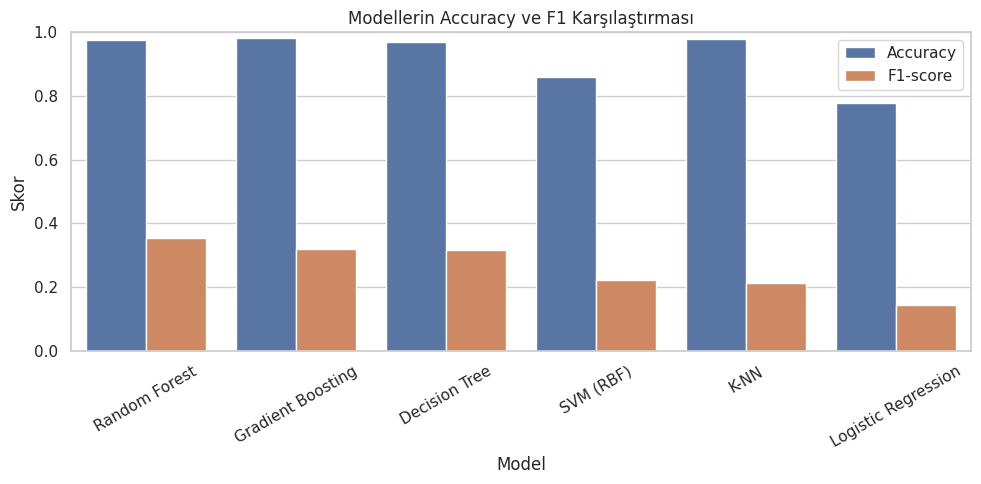

In [ ]:

# 1) Gerekli kütüphaneler
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model     import LogisticRegression
from sklearn.tree             import DecisionTreeClassifier
from sklearn.ensemble         import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors        import KNeighborsClassifier
from sklearn.svm              import SVC

from sklearn.metrics          import accuracy_score, f1_score

# 2) Kullanılacak modeller
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
    "Decision Tree":        DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest":        RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced"),
    "K-NN":                 KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)":            SVC(kernel="rbf", probability=True, random_state=42, class_weight="balanced"),
    "Gradient Boosting":    GradientBoostingClassifier(random_state=42)
}

# 3) Eğitim, tahmin, metrik hesaplama

results = []

for name, model in models.items():
    model.fit(X_train, y_train)            # eğit
    y_pred = model.predict(X_test)         # tahmin et

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average="binary")

    results.append({"Model": name, "Accuracy": acc, "F1-score": f1})

# 4) Sonuçları DataFrame’e dönüştür
results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
print(results_df)

# 5) Bar grafiğiyle görselleştir
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df.melt(id_vars="Model", value_vars=["Accuracy", "F1-score"]),
            x="Model", y="value", hue="variable")
plt.title("Modellerin Accuracy ve F1 Karşılaştırması")
plt.ylabel("Skor")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.legend(title="")
plt.tight_layout()
plt.show()

Veri setinde "churn" oranı sadece %2 (1033/50000) olduğundan, modellerin çoğu “churn yok (0)” diyerek yüksek doğruluk alıyor.
Ancak bu durumda gerçek churn’leri yakalayamıyorlar, bu yüzden F1-score daha düşük kalıyor.

**6. Her Model için Confusion Matrix Görselleştirmesi**

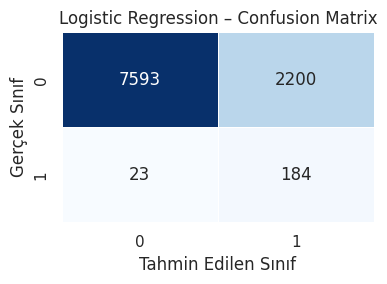

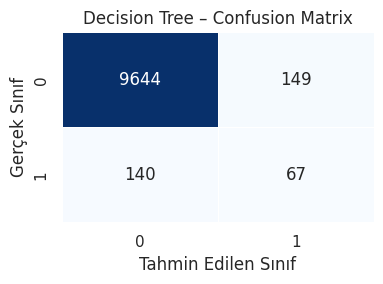

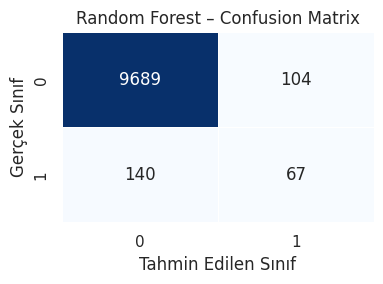

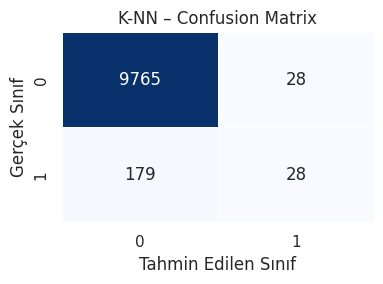

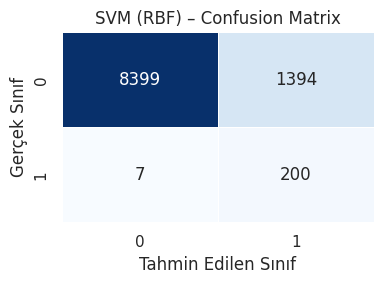

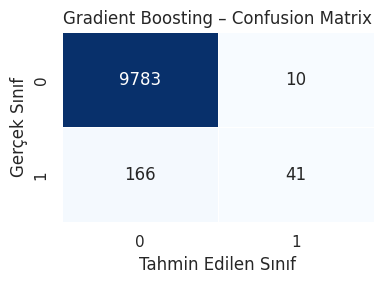

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Eğer "models" sözlüğündeki modeller hâlâ bellekteyse doğrudan kullan
# (Aksi durumda önceki hücredeki modelleri yeniden eğitmeniz gerekir.)

for name, model in models.items():
    # 1. Tahmin
    y_pred = model.predict(X_test)

    # 2. Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # 3. Görselleştirme
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm,
                annot=True,       # hücrelere sayı yaz
                fmt="d",          # tam sayı formatı
                cmap="Blues",
                cbar=False,
                linewidths=0.5)

    plt.title(f"{name} – Confusion Matrix")
    plt.xlabel("Tahmin Edilen Sınıf")
    plt.ylabel("Gerçek Sınıf")
    plt.tight_layout()
    plt.show()

| Hücre  | Anlamı                                                           |
| ------ | ---------------------------------------------------------------- |
| *TN* | Gerçekte *0* (churn yok) & doğru tahmin                        |
| *FP* | Gerçekte *0* ama *1* tahmin edildi (yalancı pozitif)         |
| *FN* | Gerçekte *1* (churn) ama *0* tahmin edildi (yalancı negatif) |
| *TP* | Gerçekte *1* & doğru tahmin                                    |

**7. XGBoost Modelinin Eğitimi, Değerlendirmesi ve Confusion Matrix Çizimi**

Accuracy: 0.9305

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      9793
           1       0.20      0.79      0.32       207

    accuracy                           0.93     10000
   macro avg       0.60      0.86      0.64     10000
weighted avg       0.98      0.93      0.95     10000



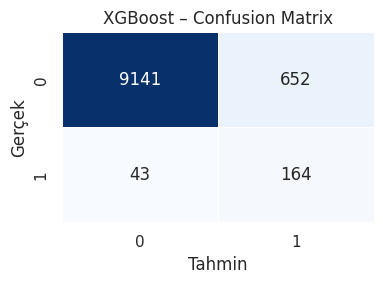

              precision    recall  f1-score     support
0              0.995318  0.933422  0.963377   9793.0000
1              0.200980  0.792271  0.320626    207.0000
accuracy       0.930500  0.930500  0.930500      0.9305
macro avg      0.598149  0.862846  0.642001  10000.0000
weighted avg   0.978875  0.930500  0.950072  10000.0000


In [ ]:
# 1) Kütüphane kurulumu (Colab’de henüz yoksa)
!pip install -q xgboost

# 2) Gerekli kütüphaneler
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 3) Sınıf dengesizliğini dengelemek için scale_pos_weight hesaplayalım
pos = y_train.sum()            # pozitif (churn) örnek sayısı
neg = len(y_train) - pos       # negatif örnek sayısı
scale_pos = neg / pos          # basit denge katsayısı

# 4) Model oluştur ve eğit
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos,    # dengesiz sınıflar için kritik
    random_state=42
)

xgb_model.fit(X_train, y_train)

# 5) Tahmin ve metrikler
y_pred = xgb_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}\n")

print("Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 6) Confusion matrix görselleştirme
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5)
plt.title("XGBoost – Confusion Matrix")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(y_test, y_pred, output_dict=True)
df_report = pd.DataFrame(report).transpose()
print(df_report)


TN (9141): Model, sınıfı doğru şekilde "0" olarak tahmin etmiş.

FP (652): Model, aslında "0" olanları yanlışlıkla "1" olarak tahmin etmiş.

FN (43): Model, aslında "1" olanları yanlışlıkla "0" olarak tahmin etmiş.

TP (164): Model, sınıfı doğru şekilde "1" olarak tahmin etmiş.  
Çok fazla churn yok(0) var ve bu durum gerçek churn’leri yakalayamada hata yaratabiliyor.

**8. XGBoost Özellik Önem Değerlendirmesi**

<ipython-input-58-d898ae5fd442>:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


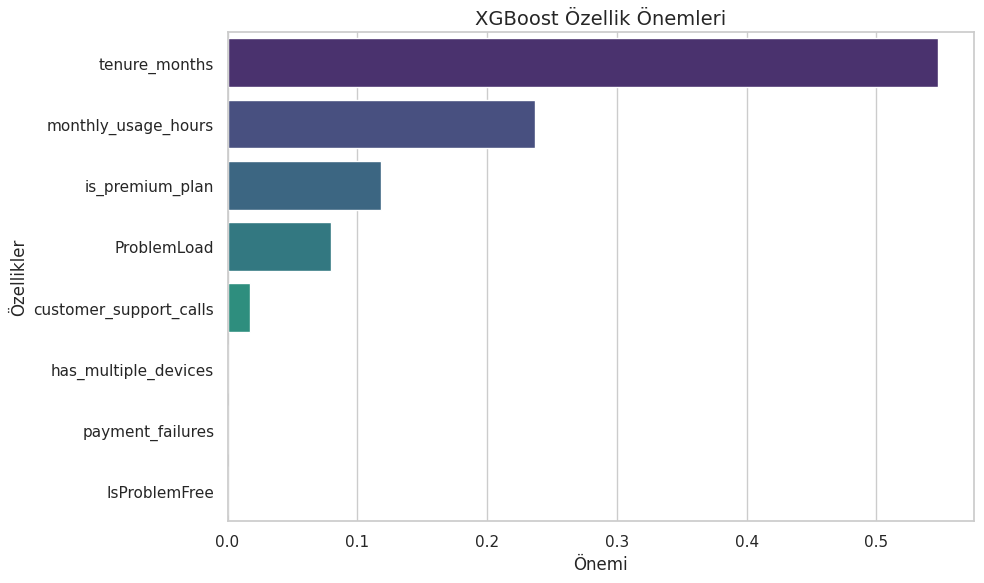

In [ ]:
import xgboost as xgb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# XGBoost modelini eğittiğini varsayıyoruz:
# model = xgb.XGBClassifier(...)
# model.fit(X_train_scaled, y_train)

# Özellik isimlerini ve önem değerlerini al
feature_importances = model.feature_importances_
feature_names = X_train.columns  # Orijinal feature isimleri

# DataFrame’e dönüştür
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
})

# Önem sırasına göre sırala
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Barplot çizimi
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('XGBoost Özellik Önemleri', fontsize=14)
plt.xlabel('Önemi')
plt.ylabel('Özellikler')
plt.tight_layout()
plt.show()

**9. SHAP ile Model Açıklanabilirliği**

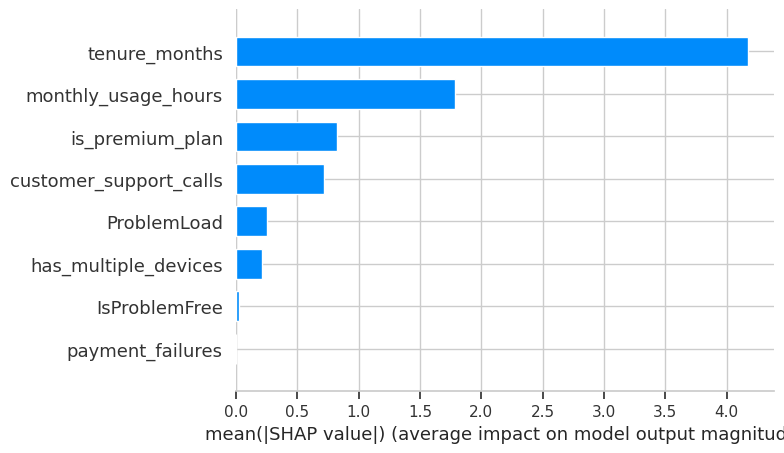

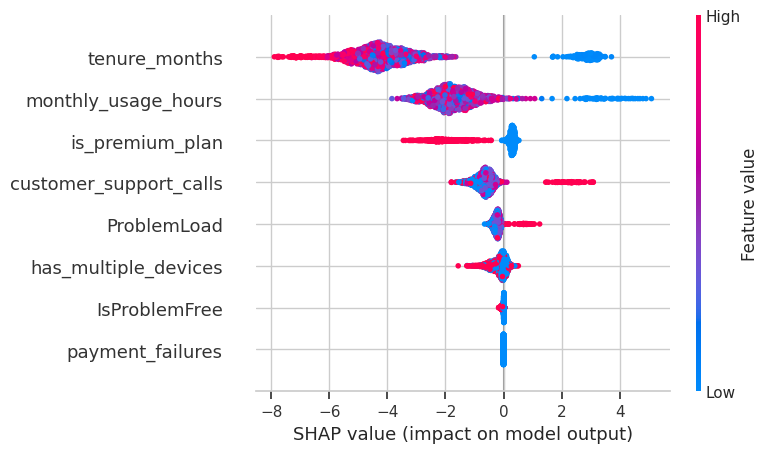

In [ ]:
# ------------------------------------------------------------
# 1) SHAP kurulumu  (yalnızca ilk kez gerekir)
!pip install -q shap

# 2) Gerekli modüller
import shap
import numpy as np

# 3) SHAP’i başlat (notebook çıktısı için)
shap.initjs()

# 4) TreeExplainer oluştur (XGBoost modeliniz xgb_model ise)
explainer = shap.TreeExplainer(xgb_model)

# 5) Hesaplama – test setinden (veya tamamından) SHAP değerleri
#   ⏱  Test seti büyükse, rastgele 2000 satır seçip hızlandırabilirsiniz
idx = np.random.choice(X_test.index, size=2000, replace=False) if len(X_test) > 2000 else X_test.index
shap_values = explainer.shap_values(X_test.loc[idx])

# 6-A) Öznitelik önem sıralaması (bar chart)
shap.summary_plot(shap_values, X_test.loc[idx], plot_type="bar", show=True)

# 6-B) Tam dağılımı gösteren beeswarm grafiği
shap.summary_plot(shap_values, X_test.loc[idx], show=True)

SHAP avantajı: Hem “hangi değişken daha önemli?” sorusuna (bar), hem de “değişkenin hangi değer aralıkları churn olasılığını nasıl değiştiriyor?” sorusuna (beeswarm) yanıt verir.

**1. SHAP Bar Plot (Özellik Önem Sıralaması)**
En üstteki değişkenler: Modelin churn tahmininde en çok dikkate aldığı sütunlar.

Örneğin, customer_support_calls (müşteri destek çağrıları) en yüksekse, bu değişken churn üzerinde çok güçlü bir etkiye sahip demektir.

payment_failures (ödeme başarısızlıkları) veya tenure_months (müşterinin abonelik süresi) gibi diğer değişkenler de önemli olabilir.

Bu grafik sadece “hangi değişkenin etkisi daha fazla?” sorusuna cevap verir, etkilerin yönünü göstermez.

**2. SHAP Beeswarm Plot (Değişken Değerlerinin Etkisi ve Yönü)**
Grafik, her bir değişkenin tüm gözlemler için SHAP değerlerini (etki şiddeti ve yönü) gösterir.

Her nokta bir müşteriye karşılık gelir.

Noktaların yatay pozisyonu: o müşterinin o özelliğinin model çıktısına (churn olasılığına) ne kadar pozitif ya da negatif etkisi olduğunu gösterir.

Noktanın rengi: o müşterideki ilgili özelliğin gerçek değeri. Kırmızı yüksek değer, mavi düşük değer demektir.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Giriş ve hedef değişkenleri belirle
selected_features = ['tenure_months', 'monthly_usage_hours', 'has_multiple_devices',
                     'customer_support_calls', 'payment_failures', 'is_premium_plan',
                     'ProblemLoad', 'IsProblemFree']
X_selected = df[selected_features]
y = df['churn']

# 2. Eğitim ve test setine ayır (stratify ile dengesizliği koru)
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y)

# 3. Sayısal sütunları ölçekle
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Modelleri tanımla
models = {
    "Lojistik Regresyon": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Karar Ağacı": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

# 5. Modelleri eğit, tahmin yap ve sonuçları yazdır
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append((name, acc, f1))
    print(f"🔹 {name}\n   Accuracy: {acc:.3f} | F1 Score: {f1:.3f}\n{'-'*40}")

# 6. Sonuçları DataFrame'e dönüştür
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'F1-score'])
print(results_df)

🔹 Lojistik Regresyon
   Accuracy: 0.980 | F1 Score: 0.028
----------------------------------------
🔹 KNN
   Accuracy: 0.978 | F1 Score: 0.245
----------------------------------------
🔹 Karar Ağacı
   Accuracy: 0.973 | F1 Score: 0.364
----------------------------------------
🔹 Random Forest
   Accuracy: 0.976 | F1 Score: 0.358
----------------------------------------
🔹 SVM
   Accuracy: 0.979 | F1 Score: 0.000
----------------------------------------
🔹 Gradient Boosting
   Accuracy: 0.982 | F1 Score: 0.318
----------------------------------------
                Model  Accuracy  F1-score
0  Lojistik Regresyon    0.9795  0.028436
1                 KNN    0.9784  0.244755
2         Karar Ağacı    0.9728  0.364486
3       Random Forest    0.9760  0.358289
4                 SVM    0.9793  0.000000
5   Gradient Boosting    0.9824  0.317829


| Model                   | Accuracy (Tablo 1) | F1 Score (Tablo 1) | Accuracy (Tablo 2) | F1 Score (Tablo 2) |
| ----------------------- | ------------------ | ------------------ | ------------------ | ------------------ |
| *Logistic Regression* | 0.7777             | 0.1420             | 0.9795             | 0.0284             |
| *K-NN*                | 0.9793             | 0.2129             | 0.9784             | 0.2448             |
| *Decision Tree*       | 0.9711             | 0.3168             | 0.9728             | 0.3645             |
| *Random Forest*       | 0.9756             | 0.3545             | 0.9760             | 0.3583             |
| *SVM (RBF)*           | 0.8599             | 0.2221             | 0.9793             | 0.0000             |
| *Gradient Boosting*   | 0.9824             | 0.3178             | 0.9824             | 0.3178             |

| Kriter                 | En İyi Model                           |
| ---------------------- | -------------------------------------- |
| *Accuracy*           | Gradient Boosting (0.9824)             |
| *F1-score*           | Decision Tree (0.3645)                 |
| *Dengeli Performans* | Random Forest (iyi accuracy ve iyi F1) |


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

# Hiperparametre aralıklarını belirle
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# GridSearchCV nesnesi oluştur
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1',   # F1 skoruna göre en iyi modeli seç
    cv=5,
    n_jobs=-1,
    verbose=2
)

# Modeli eğitim verisi üzerinde eğit
grid_search.fit(X_train, y_train)

# En iyi modeli al
best_rf = grid_search.best_estimator_

print("En iyi hiperparametreler:", grid_search.best_params_)

# En iyi model ile test verisi üzerinde tahmin yap
y_pred = best_rf.predict(X_test)

# Performans raporu
print("Classification Report:\n", classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
En iyi hiperparametreler: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      9793
           1       0.39      0.33      0.36       207

    accuracy                           0.98     10000
   macro avg       0.69      0.66      0.67     10000
weighted avg       0.97      0.98      0.97     10000

Confusion Matrix:
 [[9686  107]
 [ 139   68]]


| Sınıf                    | Precision | Recall | F1-score | Support (Örnek Sayısı) |
| ------------------------ | --------- | ------ | -------- | ---------------------- |
| 0 (Müşteri kalır)        | 0.99      | 0.99   | 0.99     | 9793                   |
| 1 (Churn: Müşteri kaybı) | 0.39      | 0.33   | 0.36     | 207                    |

Model çok iyi genel doğruluk ve churn olmayan müşterilerde yüksek başarı sağlıyor.

Ancak churn sınıfını tahmin etme başarısı düşük.

Bu durum genellikle veri setinde sınıf dengesizliği (churn çok az örnek) olduğunda görülür.

🎯 En İyi Random Forest Modeli (GridSearch sonrası)
Accuracy: 0.975
F1 Score: 0.356

Sınıflandırma Raporu:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      9793
           1       0.39      0.33      0.36       207

    accuracy                           0.98     10000
   macro avg       0.69      0.66      0.67     10000
weighted avg       0.97      0.98      0.97     10000



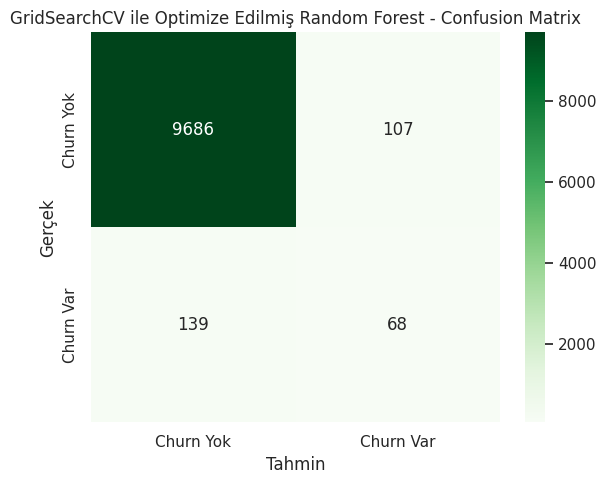

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Tahmin yap
y_pred_best_rf = best_rf.predict(X_test)

# Performans çıktısı
print("🎯 En İyi Random Forest Modeli (GridSearch sonrası)")
print(f"Accuracy: {accuracy_score(y_test, y_pred_best_rf):.3f}")
print(f"F1 Score: {f1_score(y_test, y_pred_best_rf):.3f}")
print("\nSınıflandırma Raporu:\n", classification_report(y_test, y_pred_best_rf))

# Confusion Matrix
cm_best = confusion_matrix(y_test, y_pred_best_rf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Churn Yok", "Churn Var"], yticklabels=["Churn Yok", "Churn Var"])
plt.title("GridSearchCV ile Optimize Edilmiş Random Forest - Confusion Matrix")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

In [ ]:
df.head()

,tenure_months,monthly_usage_hours,has_multiple_devices,customer_support_calls,payment_failures,is_premium_plan,churn,ProblemLoad,IsProblemFree
0,39.0,30.953928,0,1.0,0.0,0,0,1.0,0
1,52.0,20.485203,0,0.0,0.0,0,0,0.0,1
2,29.0,21.684462,0,1.0,0.0,0,0,1.0,0
3,15.0,27.894281,0,1.0,0.0,1,0,1.0,0
4,43.0,19.250190,1,1.0,0.0,0,0,1.0,0


**10. Rastgele Seçilen 5 Müşteri için Churn Kalma Olasılığı Tahmini**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Doğru sütunları belirle
selected_features = ['tenure_months', 'monthly_usage_hours', 'payment_failures']
X_selected = df[selected_features]
y = df['churn']

# Eğitim-test bölme
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

# Ölçekleme
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model oluştur (veya daha önce eğittiysen yükle)
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Random 5 örnek seç
random_samples = X_test.sample(5, random_state=42)
random_samples_scaled = scaler.transform(random_samples)

# Tahmin
probabilities = rf_model.predict_proba(random_samples_scaled)

# Sonuçları yazdır
results = pd.DataFrame({
    'tenure_months': random_samples['tenure_months'].values,
    'monthly_usage_hours': random_samples['monthly_usage_hours'].values,
    'payment_failures': random_samples['payment_failures'].values,
    'Predicted_Churn_Prob': probabilities[:, 1]
})

print(results)

   tenure_months  monthly_usage_hours  payment_failures  Predicted_Churn_Prob
0           12.0            21.861503               0.0                  0.00
1           33.0            15.997776               0.0                  0.00
2            5.0            12.578368               0.0                  0.06
3           26.0            10.690904               0.0                  0.00
4           42.0            19.212024               0.0                  0.00


SINIFLANDIRMA KULLANDIK

Dengesiz Veri Seti:
Veri setinizde churn (1) sınıfı çok azsa, model genellikle “churn olmaz” (0) tahmininde yüksek güvenle bulunabilir. Bu yüzden çoğu olasılık 0 civarında çıkabilir.

Modelin Öğrenme Durumu:
Model yeterince karmaşık veya iyi eğitilmemiş olabilir. Ama genelde Random Forest dengesiz sınıflar için biraz daha iyi sonuç verir.

Ölçeklendirme ve Özellikler:
Seçilen örnekler ölçeklendirilmiş değerler. Bu nedenle bazı düşük olasılıkların çıkması normal, özellikle de churn oranı düşükse.

Eşik Değeri:
Burada sadece olasılıkları gösteriyoruz. Model, genelde 0.5 üzeri olasılıkları “churn” olarak sınıflandırır. 0.07 olasılık bile “churn değil” olarak yorumlanır.

Model çoğunlukla müşteri kaybı yaşanmayacağını düşünüyor (çoğunluk sınıfı hakim).

Bir örneğin 0.07 olasılık göstermesi, o müşterinin kaybetme ihtimalinin görece diğerlerine göre biraz daha yüksek olduğunu gösteriyor ama hala düşük.

**11. Yeni Bir Müşteri Profili Üzerinden Tahmin**

In [ ]:
import numpy as np
import pandas as pd

# Modelin eğitimde kullandığı özellikler
model_features = ['tenure_months', 'monthly_usage_hours', 'payment_failures']

# Yeni müşteri verisi
new_customer = {
    'tenure_months': 12,
    'monthly_usage_hours': 50,
    'has_multiple_devices': 1,
    'customer_support_calls': 2,
    'payment_failures': 0,
    'is_premium_plan': 0,
    'ProblemLoad': 1,
    'IsProblemFree': 0
}

# DataFrame oluştur
new_cust_df = pd.DataFrame([new_customer])

# Ölçeklenecek sütunlar
scaled_cols = ['tenure_months', 'monthly_usage_hours']

# Ölçekleme işlemi (sadece scaled olanlar)
new_cust_df[scaled_cols] = scaler.transform(new_cust_df[scaled_cols])

# Modelin beklediği sütunları al (sıra önemli)
model_input = new_cust_df[model_features]

# Tahmin yap
churn_prob = best_rf.predict_proba(model_input)[:, 1][0]
print(f"Yeni müşteri için churn olasılığı: {churn_prob:.4f}")


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


ValueError: X has 3 features, but RandomForestClassifier is expecting 2 features as input.